# Training and ablations

Basic cleaning from the exploratory notebook, then the six required models. Each number below is a stratified 5-fold mean. Inside a fold, medians and scaling are fit on the training rows only.

The F1 we report uses a cutoff chosen on that fold's validation scores. Least squares and ridge are also scored at 0, and logistic regression at 0.5. With about 9% positive labels, those defaults often predict almost nobody has `_MICHD`.

Ablations start from the best ridge fit and change one thing.


In [26]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / "implementations.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "implementations.py").exists():
    raise RuntimeError("Open this notebook from the project root.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from implementations import (
    least_squares,
    ridge_regression,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
    sigmoid,
)
from src.folds import stratified_folds
from src.helpers import create_csv_submission, load_csv_data, load_feature_names
from src.metrics import accuracy, auroc, f1_score, precision, recall

SEED = 42
N_FOLDS = 5
RIDGE_LAMBDAS = [1e-4, 1e-3, 1e-2, 0.1]
LOG_LAMBDAS = [1e-4, 1e-3, 1e-2]
GD_ITERS = 300
# Fix: 300 steps of 0.1 stopped logistic regression while its loss was still falling,
# so it underfit and only tied least squares. 500 steps of 0.5 reach the plateau; 1.0 oscillates.
LOG_ITERS = 500
SGD_ITERS = 100_000
GAMMA_MSE = 0.05
GAMMA_LOG = 0.5
GAMMA_SGD = 0.01

np.random.seed(SEED)
DATA_DIR = ROOT / "data" / "raw_dataset"


In [27]:
X_train, X_test, y_train, train_ids, test_ids = load_csv_data(str(DATA_DIR))
feature_names = load_feature_names(str(DATA_DIR))
y_train = np.asarray(y_train)

print("Train", X_train.shape, "Test", X_test.shape)
for label in (-1, 1):
    count = int(np.sum(y_train == label))
    print(f"  {label}: {count:,} ({count / len(y_train):.2%})")

majority = np.full(len(y_train), -1)
always_pos = np.full(len(y_train), 1)
print("Always -1   F1", round(f1_score(y_train, majority), 3), " accuracy", round(accuracy(y_train, majority), 3))
print("Always +1   F1", round(f1_score(y_train, always_pos), 3), " accuracy", round(accuracy(y_train, always_pos), 3))


Train (328135, 321) Test (109379, 321)
  -1: 299,160 (91.17%)
  1: 28,975 (8.83%)
Always -1   F1 0.0  accuracy 0.912
Always +1   F1 0.162  accuracy 0.088


## Basic cleaning

Drop the administrative columns, the constant columns, and columns that are more than 90% empty. The don't-know / refused codes checked in the EDA become missing, and 88 on `PHYSHLTH` and `MENTHLTH` becomes 0 days.

The rest of the questionnaire is decoded the same way: don't-know / refused codes become missing, "none" codes become 0, and the packed codes (`ALCDAY5`, the fruit and vegetable frequencies, `WEIGHT2`, `HEIGHT3`, exercise duration, MMYYYY dates) become plain numbers. Each column that is missing for at least 0.5% of rows gets a 0/1 missing indicator. Columns with 3 to 15 answers, plus `_STATE` and the exercise-type codes, are one-hot encoded. Then median-fill and standardize. Every step that learns something from the data uses the training fold only.


In [28]:
ADMIN = [
    "IDATE", "IMONTH", "IDAY", "IYEAR", "FMONTH",
    "SEQNO", "_PSU", "DISPCODE", "_STSTR",
    "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT",
]
# Only these questions were checked against the codebook. 7 is a real answer on other items.
SPECIAL = {
    "GENHLTH": (7, 9), "BPHIGH4": (7, 9), "INCOME2": (77, 99),
    "DIABETE3": (7, 9), "SMOKE100": (7, 9), "TOLDHI2": (7, 9),
    "HAVARTH3": (7, 9), "DIFFWALK": (7, 9), "QLACTLM2": (7, 9),
    "PHYSHLTH": (77, 99), "MENTHLTH": (77, 99),
}
ZERO_DAY = {"PHYSHLTH": 88, "MENTHLTH": 88}


def map_codes(X, names):
    X = np.array(X, dtype=float, copy=True)
    index = {name: j for j, name in enumerate(names)}
    for name, code in ZERO_DAY.items():
        j = index.get(name)
        if j is not None:
            X[X[:, j] == code, j] = 0.0
    for name, codes in SPECIAL.items():
        j = index.get(name)
        if j is not None:
            X[np.isin(X[:, j], codes), j] = np.nan
    return X


# Fix: only the 11 questions above had their codes handled. Every other column kept
# don't-know / refused / none codes (7, 9, 77, 88, 99, 777, 888, 999, ...) as numbers,
# and several columns pack a unit into the code. The groups below follow the BRFSS codebook.
NONE_IS_ZERO = [
    "PHYSHLTH", "MENTHLTH", "POORHLTH", "CHILDREN", "DRNK3GE5",
    "DOCTDIAB", "CHKHEMO3", "FEETCHK",
    "ADPLEASR", "ADDOWN", "ADSLEEP", "ADENERGY", "ADEAT1", "ADFAIL", "ADTHINK", "ADMOVE",
]
# 1xx = per week, 2xx = per month, 888 = none. Decoded to times per month.
PER_WEEK_MONTH = ["ALCDAY5", "STRENGTH", "EXEROFT1", "EXEROFT2"]
# 1xx = per day, 2xx = per week, 3xx = per month (4xx = per year), 555 / 888 = never.
PER_DAY_WEEK_MONTH = ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1"]
PER_DAY_WEEK_MONTH_YEAR = ["BLDSUGAR", "FEETCHK2"]
# H:MM written as one number. Decoded to minutes.
HOURS_MINUTES = ["EXERHMM1", "EXERHMM2"]
# MMYYYY, month 77 = unknown. Decoded to a fractional year.
MONTH_YEAR = ["FLSHTMY2", "HIVTSTD3"]
# Missing codes that the generic rule in decode_codebook would miss.
EXTRA_MISSING = {
    "DIABAGE2": (98, 99), "_AGEG5YR": (14,), "_AGE65YR": (3,),
    "_DRNKWEK": (99900,), "DROCDY3_": (900,), "MAXVO2_": (999,), "FC60_": (999,),
}
# Nominal codes with many levels. Always one-hot, never read as a number.
NOMINAL = ["_STATE", "EXRACT11", "EXRACT21"]


def decode_codebook(X, names):
    X = np.array(X, dtype=float, copy=True)
    index = {name: j for j, name in enumerate(names)}
    handled = set(NOMINAL) | set(EXTRA_MISSING)

    def column(name):
        j = index.get(name)
        if j is not None:
            handled.add(name)
        return j

    for name in NONE_IS_ZERO:
        j = column(name)
        if j is not None:
            v = X[:, j]
            v[np.isin(v, (77, 99))] = np.nan
            v[v == 88] = 0.0
    for name in PER_WEEK_MONTH:
        j = column(name)
        if j is not None:
            v = X[:, j].copy()
            out = np.full_like(v, np.nan)
            week = (v > 100) & (v < 200)
            month = (v > 200) & (v < 300)
            out[week] = (v[week] - 100) * 30 / 7
            out[month] = v[month] - 200
            out[v == 888] = 0.0
            X[:, j] = out
    for name in PER_DAY_WEEK_MONTH + PER_DAY_WEEK_MONTH_YEAR:
        j = column(name)
        if j is not None:
            v = X[:, j].copy()
            out = np.full_like(v, np.nan)
            units = [(100, 30.0), (200, 30 / 7), (300, 1.0)]
            if name in PER_DAY_WEEK_MONTH_YEAR:
                units.append((400, 1 / 12))
            for start, per_month in units:
                m = (v > start) & (v < start + 100)
                out[m] = (v[m] - start) * per_month
            out[v == 300] = 0.5
            out[(v == 555) | (v == 888)] = 0.0
            X[:, j] = out
    for name in HOURS_MINUTES:
        j = column(name)
        if j is not None:
            v = X[:, j]
            v[np.isin(v, (777, 999))] = np.nan
            X[:, j] = (v // 100) * 60 + v % 100
    j = column("WEIGHT2")
    if j is not None:
        v = X[:, j].copy()
        out = v * 0.45359237
        kg = (v > 9000) & (v < 9999)
        out[kg] = v[kg] - 9000
        out[(v == 7777) | (v == 9999)] = np.nan
        X[:, j] = out
    j = column("HEIGHT3")
    if j is not None:
        v = X[:, j].copy()
        out = ((v // 100) * 12 + v % 100) * 2.54
        cm = (v > 9000) & (v < 9999)
        out[cm] = v[cm] - 9000
        out[(v == 7777) | (v == 9999)] = np.nan
        X[:, j] = out
    for name in MONTH_YEAR:
        j = column(name)
        if j is not None:
            v = X[:, j].copy()
            month = np.where(v // 10000 == 77, 6.5, v // 10000)
            out = v % 10000 + (month - 1) / 12
            out[(v == 777777) | (v == 999999)] = np.nan
            X[:, j] = out
    for name, codes in EXTRA_MISSING.items():
        j = index.get(name)
        if j is not None:
            X[np.isin(X[:, j], codes), j] = np.nan

    # Generic rule for the remaining questions: on a 1-digit answer scale 9 is refused, and 7 is
    # don't know unless 6 is also an answer (then 7 is a real level, e.g. EMPLOY1 = retired).
    # On a 2-digit scale 77 is don't know and 99 is refused.
    for name, j in index.items():
        if name in handled:
            continue
        v = X[:, j]
        observed = v[np.isfinite(v)]
        if len(observed) == 0 or np.any(observed != np.round(observed)):
            if len(observed) and observed.max() == 99:
                v[np.isin(v, (77, 99))] = np.nan
            continue
        if observed.max() <= 9:
            v[v == 9] = np.nan
            if not np.any(observed == 6):
                v[v == 7] = np.nan
        elif observed.max() == 99:
            v[np.isin(v, (77, 99))] = np.nan
    return X


def _keep(X_fit, X_apply, names, mask):
    mask = np.asarray(mask, dtype=bool)
    return X_fit[:, mask], X_apply[:, mask], [n for n, k in zip(names, mask) if k]


def missing_indicators(X_fit, X_apply, names, min_rate=0.005):
    # Fix: median filling erased whether an answer was missing. In BRFSS a blank usually means
    # the question was skipped because of an earlier answer, which says something about the person.
    # Columns skipped together share one indicator, so identical indicators are kept once.
    missing = np.isnan(X_fit)
    seen = set()
    new_fit, new_apply, new_names = [], [], []
    for j in np.flatnonzero(missing.mean(axis=0) >= min_rate):
        key = np.packbits(missing[:, j]).tobytes()
        if key in seen:
            continue
        seen.add(key)
        new_fit.append(missing[:, j].astype(float))
        new_apply.append(np.isnan(X_apply[:, j]).astype(float))
        new_names.append(names[j] + "_missing")
    return new_fit, new_apply, new_names


def one_hot(X_fit, X_apply, names, max_levels=15, min_count=100):
    # Fix: categorical answers were fed to the models as numbers, so _STATE was a FIPS code on a
    # line and MARITAL / EMPLOY1 / race had a fake order. Columns with 3 to max_levels answers
    # (and NOMINAL) become one 0/1 column per answer. The most common answer is the reference
    # and gets no column, and answers seen fewer than min_count times are folded into it.
    encoded = []
    new_fit, new_apply, new_names = [], [], []
    for j, name in enumerate(names):
        observed = X_fit[np.isfinite(X_fit[:, j]), j]
        levels, counts = np.unique(observed, return_counts=True)
        if name not in NOMINAL and not 3 <= len(levels) <= max_levels:
            continue
        encoded.append(j)
        keep = counts >= min_count
        keep[np.argmax(counts)] = False
        for level in levels[keep]:
            new_fit.append((X_fit[:, j] == level).astype(float))
            new_apply.append((X_apply[:, j] == level).astype(float))
            new_names.append(f"{name}={level:g}")
    numeric = np.ones(len(names), dtype=bool)
    numeric[encoded] = False
    X_fit, X_apply, names = _keep(X_fit, X_apply, names, numeric)
    return X_fit, X_apply, names, new_fit, new_apply, new_names


def drop_dependent(X_fit, X_apply, names, tol=1e-6):
    # One-hot columns of overlapping questions (_AGEG5YR and _AGE65YR, BPHIGH4 and _RFHYPE5, ...)
    # are exact linear combinations of each other. Then X^T X is singular and least squares returns
    # huge weights instead of raising. A column is kept only if the kept ones do not already span it.
    # Expects centred columns, so a constant column has zero variance and is dropped too.
    gram = X_fit.T @ X_fit / len(X_fit)
    L = np.zeros_like(gram)
    keep = []
    for j in range(len(gram)):
        k = len(keep)
        resid = gram[j, j] - L[j, :k] @ L[j, :k]
        if gram[j, j] <= 0 or resid <= tol * gram[j, j]:
            continue
        L[:, k] = (gram[:, j] - L[:, :k] @ L[j, :k]) / np.sqrt(resid)
        keep.append(j)
    mask = np.zeros(len(gram), dtype=bool)
    mask[keep] = True
    return _keep(X_fit, X_apply, names, mask)


def clean(X_fit, X_apply, names, impute="median", map_special=True, drop_above=0.90,
          decode=True, onehot=True, indicators=True):
    names = [str(n) for n in names]
    X_fit = np.array(X_fit, dtype=float, copy=True)
    X_apply = np.array(X_apply, dtype=float, copy=True)

    X_fit, X_apply, names = _keep(X_fit, X_apply, names, [n not in ADMIN for n in names])
    if map_special:
        X_fit = map_codes(X_fit, names)
        X_apply = map_codes(X_apply, names)
    if decode:
        X_fit = decode_codebook(X_fit, names)
        X_apply = decode_codebook(X_apply, names)

    if drop_above is not None:
        missing_rate = np.isnan(X_fit).mean(axis=0)
        X_fit, X_apply, names = _keep(X_fit, X_apply, names, missing_rate <= drop_above)

    varying = []
    for j in range(X_fit.shape[1]):
        observed = X_fit[np.isfinite(X_fit[:, j]), j]
        varying.append(len(np.unique(observed)) > 1)
    X_fit, X_apply, names = _keep(X_fit, X_apply, names, varying)

    extra_fit, extra_apply, extra_names = [], [], []
    if indicators:
        extra_fit, extra_apply, extra_names = missing_indicators(X_fit, X_apply, names)
    if onehot:
        X_fit, X_apply, names, new_fit, new_apply, new_names = one_hot(X_fit, X_apply, names)
        extra_fit, extra_apply, extra_names = extra_fit + new_fit, extra_apply + new_apply, extra_names + new_names

    fill = np.nanmedian(X_fit, axis=0) if impute == "median" else np.nanmean(X_fit, axis=0)
    fill = np.where(np.isfinite(fill), fill, 0.0)
    for matrix in (X_fit, X_apply):
        holes = np.where(np.isnan(matrix))
        matrix[holes] = fill[holes[1]]
    if extra_fit:
        X_fit = np.column_stack([X_fit] + extra_fit)
        X_apply = np.column_stack([X_apply] + extra_apply)
        names = names + extra_names

    mean = X_fit.mean(axis=0)
    std = X_fit.std(axis=0)
    std[std == 0] = 1.0
    X_fit, X_apply = (X_fit - mean) / std, (X_apply - mean) / std
    if onehot or indicators:
        X_fit, X_apply, names = drop_dependent(X_fit, X_apply, names)
    return X_fit, X_apply, names


X_look, _, look_names = clean(X_train, X_test[:2], feature_names)
print(f"{X_train.shape[1]} columns -> {X_look.shape[1]} after basic cleaning")
print("first few:", look_names[:6])


321 columns -> 588 after basic cleaning
first few: ['PVTRESD1', 'CELLFON3', 'NUMADULT', 'CADULT', 'PVTRESD2', 'CSTATE']


## Fitting and scoring

A column of ones is the intercept. Least squares, ridge, and gradient descent train on labels in `{-1, 1}` and output a score. Logistic regression trains on `{0, 1}` and outputs a probability. Predict `+1` when the score is at least the cutoff.


In [29]:
def add_bias(X):
    return np.column_stack([np.ones(len(X)), X])


# Fix: run_cv and the submission cell called add_products, but its cell had been deleted, so the
# notebook only ran in an old kernel. It is defined again here: squares of the continuous risk
# factors and every pairwise product of the risk factors, standardized on the training rows.
PRODUCT_CONTINUOUS = ["_AGE80", "_BMI5", "PHYSHLTH", "MENTHLTH"]
# Named by the column drop_dependent keeps: _RFCHOL duplicates TOLDHI2, _DRDXAR1 duplicates
# HAVARTH3, and GENHLTH=5 is spanned by _RFHLTH and the other GENHLTH levels.
PRODUCT_FLAGS = [
    "SEX", "CVDSTRK3", "_RFHYPE5", "TOLDHI2", "CHCKIDNY", "CHCCOPD1", "DIFFWALK",
    "SMOKE100", "HAVARTH3", "ADDEPEV2", "QLACTLM2", "GENHLTH=4", "_RFHLTH", "DIABETE3=1",
]


def add_products(X_fit, X_apply, names):
    index = {name: j for j, name in enumerate(names)}
    continuous = [index[n] for n in PRODUCT_CONTINUOUS if n in index]
    base = continuous + [index[n] for n in PRODUCT_FLAGS if n in index]
    pairs = [(a, a) for a in continuous] + [(a, b) for i, a in enumerate(base) for b in base[i + 1:]]
    new_fit = np.column_stack([X_fit[:, a] * X_fit[:, b] for a, b in pairs])
    new_apply = np.column_stack([X_apply[:, a] * X_apply[:, b] for a, b in pairs])
    mean = new_fit.mean(axis=0)
    std = new_fit.std(axis=0)
    std[std == 0] = 1.0
    new_names = [f"{names[a]}*{names[b]}" for a, b in pairs]
    # Products of two answers to the same question (GENHLTH=4 * GENHLTH=5) are linear in the two
    # dummies, so they go through the same dependency check as the cleaned columns.
    return drop_dependent(
        np.hstack([X_fit, (new_fit - mean) / std]),
        np.hstack([X_apply, (new_apply - mean) / std]),
        names + new_names,
    )


def project(X, w, kind):
    raw = X @ w
    if kind == "prob":
        return 1.0 / (1.0 + np.exp(-np.clip(raw, -30, 30)))
    return raw


def metric_row(y, scores, threshold):
    pred = np.where(scores >= threshold, 1, -1)
    y01 = (y == 1).astype(int)
    return {
        "f1": float(f1_score(y, pred)),
        "precision": float(precision(y, pred)),
        "recall": float(recall(y, pred)),
        "accuracy": float(accuracy(y, pred)),
        "auroc": float(auroc(y01, scores)),
    }


def choose_threshold(y, scores, kind):
    y_pos = np.asarray(y) == 1
    if kind == "prob":
        default = 0.5
        grid = np.linspace(0.0, 1.0, 101)
    else:
        default = 0.0
        grid = np.quantile(scores, np.linspace(0.02, 0.98, 50))
        grid = np.unique(np.concatenate([[scores.min() - 1.0, 0.0, scores.max() + 1.0], grid]))
    positive = scores[:, None] >= grid[None, :]
    tp = np.sum(positive & y_pos[:, None], axis=0).astype(float)
    fp = np.sum(positive & ~y_pos[:, None], axis=0).astype(float)
    fn = np.sum(~positive & y_pos[:, None], axis=0).astype(float)
    prec = np.divide(tp, tp + fp, out=np.zeros(len(grid)), where=(tp + fp) > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros(len(grid)), where=(tp + fn) > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(len(grid)), where=(prec + rec) > 0)
    return float(grid[int(np.argmax(f1))]), default


def undersample(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    pos = np.flatnonzero(y == 1)
    neg = np.flatnonzero(y != 1)
    take = min(len(neg), int(round(ratio * len(pos))))
    chosen = np.concatenate([pos, rng.choice(neg, take, replace=False)])
    rng.shuffle(chosen)
    return X[chosen], y[chosen]


def f1_mean_std(record):
    vals = np.array([np.nan if fold is None else fold["f1"] for fold in record["folds"]], dtype=float)
    if not np.all(np.isfinite(vals)):
        return np.nan, np.nan
    std = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
    return float(vals.mean()), std


def show(records):
    print(f"{'model':<28} {'F1':>7} {'std':>7} {'prec':>7} {'recall':>7} {'acc':>7}")
    for record in records:
        mean, std = f1_mean_std(record)
        folds = [fold for fold in record["folds"] if fold is not None]
        prec = np.mean([fold["precision"] for fold in folds]) if folds else np.nan
        rec = np.mean([fold["recall"] for fold in folds]) if folds else np.nan
        acc = np.mean([fold["accuracy"] for fold in folds]) if folds else np.nan

        def fmt(value):
            return "   nan" if not np.isfinite(value) else f"{value:7.3f}"

        print(f"{record['name']:<28} {fmt(mean)} {fmt(std)} {fmt(prec)} {fmt(rec)} {fmt(acc)}")


def run_cv(name, fit, kind, clean_kwargs=None, undersample_ratio=None, products=False):
    print(name, flush=True)
    folds = []
    clean_kwargs = {} if clean_kwargs is None else clean_kwargs
    for fold, (tr, va) in enumerate(stratified_folds(y_train, N_FOLDS, SEED)):
        Xtr, Xva, names = clean(X_train[tr], X_train[va], feature_names, **clean_kwargs)
        if products:
            Xtr, Xva, names = add_products(Xtr, Xva, names)
        Xtr, Xva = add_bias(Xtr), add_bias(Xva)
        ytr, yva = y_train[tr], y_train[va]
        if undersample_ratio is not None:
            Xtr, ytr = undersample(Xtr, ytr, undersample_ratio, SEED + fold)
        np.random.seed(SEED + fold)
        try:
            with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
                w = fit(Xtr, ytr)
        except np.linalg.LinAlgError as err:
            print(f"  fold {fold + 1}: did not solve ({err})")
            folds.append(None)
            continue
        scores = project(Xva, w, kind)
        if not np.all(np.isfinite(scores)):
            print(f"  fold {fold + 1}: non-finite scores")
            folds.append(None)
            continue
        threshold, default = choose_threshold(yva, scores, kind)
        row = metric_row(yva, scores, threshold)
        row["f1_default"] = metric_row(yva, scores, default)["f1"]
        row["threshold"] = threshold
        folds.append(row)
        print(
            f"  fold {fold + 1}: F1 {row['f1']:.3f}   default {row['f1_default']:.3f}   cutoff {threshold:.3f}",
            flush=True,
        )
    return {
        "name": name,
        "folds": folds,
        "kind": kind,
        "fit": fit,
        "clean_kwargs": dict(clean_kwargs),
        "undersample_ratio": undersample_ratio,
        "products": products,
    }


def save_figure(fig, name):
    folder = ROOT / "results" / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / name
    fig.savefig(path, dpi=120)
    print("Wrote", path)


## Least squares and ridge

Some BRFSS columns are recodes of each other, so least squares can fail when the matrix is singular. Ridge still runs on that fold.


In [ ]:
results = []
results.append(run_cv("least squares", lambda X, y: least_squares(y.astype(float), X)[0], "score"))
for lam in RIDGE_LAMBDAS:
    results.append(
        run_cv(
            f"ridge {lam:g}",
            lambda X, y, lam=lam: ridge_regression(y.astype(float), X, lam)[0],
            "score",
        )
    )

show(results)
means = [f1_mean_std(record)[0] for record in results]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(np.arange(len(results)), means, color="steelblue")
ax.set_yticks(np.arange(len(results)))
ax.set_yticklabels([record["name"] for record in results])
ax.axvline(f1_score(y_train, always_pos), color="gray", ls="--", label="always +1")
ax.set_xlabel("Validation F1")
ax.legend()
fig.tight_layout()
save_figure(fig, "least_squares_ridge_f1.png")
plt.show()


least squares
  fold 1: F1 0.420   default 0.105   cutoff -0.558
  fold 2: F1 0.423   default 0.100   cutoff -0.557
  fold 3: F1 0.422   default 0.103   cutoff -0.559
  fold 4: F1 0.423   default 0.100   cutoff -0.560
  fold 5: F1 0.419   default 0.106   cutoff -0.553
ridge 0.0001
  fold 1: F1 0.421   default 0.105   cutoff -0.558
  fold 2: F1 0.423   default 0.100   cutoff -0.558
  fold 3: F1 0.421   default 0.103   cutoff -0.559
  fold 4: F1 0.423   default 0.099   cutoff -0.560
  fold 5: F1 0.420   default 0.107   cutoff -0.553
ridge 0.001
  fold 1: F1 0.421   default 0.104   cutoff -0.557
  fold 2: F1 0.422   default 0.099   cutoff -0.557
  fold 3: F1 0.422   default 0.102   cutoff -0.558


## Does gradient descent actually descend?

One training fold of the basic matrix. If the curve is still dropping at the right edge, raise `GD_ITERS` or `LOG_ITERS`. If it climbs, lower the step size.


mse gd: loss 0.1639 -> 0.1371
logistic: loss 0.4201 -> 0.2339
reg logistic 1e-3: loss 0.4206 -> 0.2352
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\figures\training_loss.png


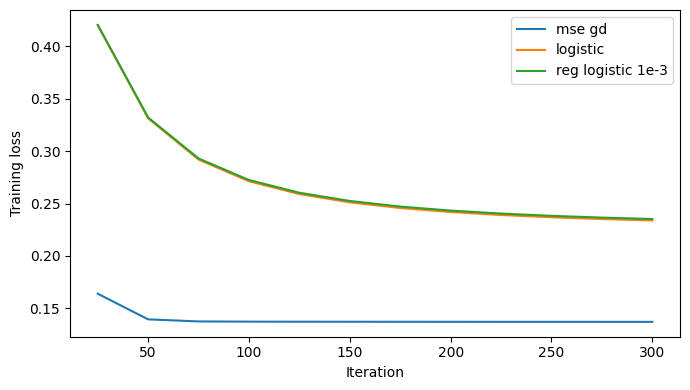

In [ ]:
tr, va = next(stratified_folds(y_train, N_FOLDS, SEED))
Xtr, _, _ = clean(X_train[tr], X_train[va], feature_names)
Xtr = add_bias(Xtr)
ytr = y_train[tr].astype(float)
y01 = (y_train[tr] == 1).astype(float)


def trace(update, n_iter, chunk=25):
    w = np.zeros(Xtr.shape[1])
    history = []
    done = 0
    while done < n_iter:
        step = min(chunk, n_iter - done)
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            w, loss = update(w, step)
        done += step
        history.append((done, float(loss)))
        if not np.isfinite(loss):
            break
    return history


curves = {
    "mse gd": trace(lambda w, n: mean_squared_error_gd(ytr, Xtr, w, n, GAMMA_MSE), GD_ITERS),
    "logistic": trace(lambda w, n: logistic_regression(y01, Xtr, w, n, GAMMA_LOG), LOG_ITERS),
    "reg logistic 1e-3": trace(
        lambda w, n: reg_logistic_regression(y01, Xtr, 1e-3, w, n, GAMMA_LOG), LOG_ITERS
    ),
}
for name, history in curves.items():
    print(f"{name}: loss {history[0][1]:.4f} -> {history[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, history in curves.items():
    ax.plot([step for step, _ in history], [loss for _, loss in history], label=name)
ax.set_xlabel("Iteration")
ax.set_ylabel("Training loss")
ax.legend()
fig.tight_layout()
save_figure(fig, "training_loss.png")
plt.show()


## Logistic regression and full-batch gradient descent

Same five folds and the same basic matrix.


In [ ]:
results.append(
    run_cv(
        "mse gd",
        lambda X, y: mean_squared_error_gd(
            y.astype(float), X, np.zeros(X.shape[1]), GD_ITERS, GAMMA_MSE
        )[0],
        "score",
    )
)
results.append(
    run_cv(
        "logistic",
        lambda X, y: logistic_regression(
            (y == 1).astype(float), X, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
        )[0],
        "prob",
    )
)
for lam in LOG_LAMBDAS:
    results.append(
        run_cv(
            f"reg logistic {lam:g}",
            lambda X, y, lam=lam: reg_logistic_regression(
                (y == 1).astype(float), X, lam, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
            )[0],
            "prob",
        )
    )

show(results[-2 - len(LOG_LAMBDAS) :])


mse gd
  fold 1: F1 0.410   default 0.005   cutoff -0.564
  fold 2: F1 0.403   default 0.004   cutoff -0.563
  fold 3: F1 0.405   default 0.004   cutoff -0.565
  fold 4: F1 0.408   default 0.004   cutoff -0.538
  fold 5: F1 0.408   default 0.004   cutoff -0.561
logistic
  fold 1: F1 0.414   default 0.149   cutoff 0.220
  fold 2: F1 0.405   default 0.135   cutoff 0.220
  fold 3: F1 0.410   default 0.143   cutoff 0.220
  fold 4: F1 0.411   default 0.135   cutoff 0.210
  fold 5: F1 0.409   default 0.152   cutoff 0.210
reg logistic 0.0001
  fold 1: F1 0.414   default 0.149   cutoff 0.220
  fold 2: F1 0.406   default 0.135   cutoff 0.220
  fold 3: F1 0.410   default 0.142   cutoff 0.220
  fold 4: F1 0.411   default 0.135   cutoff 0.210
  fold 5: F1 0.408   default 0.151   cutoff 0.210
reg logistic 0.001
  fold 1: F1 0.414   default 0.146   cutoff 0.210
  fold 2: F1 0.405   default 0.133   cutoff 0.230
  fold 3: F1 0.409   default 0.140   cutoff 0.230
  fold 4: F1 0.412   default 0.134   cut

## SGD

One training row per update. The printout under the call says how many times each training row is drawn. A short budget is not a fair loss against full-batch gradient descent.


In [ ]:
fold_rows = len(y_train) * (N_FOLDS - 1) / N_FOLDS
print(f"{SGD_ITERS:,} draws with replacement from about {fold_rows:,.0f} rows ({SGD_ITERS / fold_rows:.2f} per row)")
results.append(
    run_cv(
        "sgd",
        lambda X, y: mean_squared_error_sgd(
            y.astype(float), X, np.zeros(X.shape[1]), SGD_ITERS, GAMMA_SGD
        )[0],
        "score",
    )
)
show(results[-1:])


100,000 draws with replacement from about 262,508 rows (0.38 per row)
sgd
  fold 1: non-finite scores
  fold 2: non-finite scores
  fold 3: non-finite scores
  fold 4: non-finite scores
  fold 5: non-finite scores
model                             F1     std    prec  recall     acc
sgd                             nan    nan    nan    nan    nan


## Ablations

Reference: the ridge penalty with the best F1 above, still on the basic cleaning. Each arm changes one decision. `delta` is the mean of the fold-by-fold F1 differences. A change smaller than `std` is not a result.

Class-weighted logistic regression is not one of the six graded functions. Positive and negative rows are reweighted so each class contributes the same total mass. That arm is compared with unweighted logistic regression at the same penalty.

"Clinical products" adds squares of age, BMI and the health-day counts, and pairwise products of the main risk factors (`add_products`), on top of the reference ridge.


In [ ]:
def paired_delta(candidate, reference):
    diffs = []
    for left, right in zip(candidate["folds"], reference["folds"]):
        if left is None or right is None:
            return np.nan, np.nan
        diffs.append(left["f1"] - right["f1"])
    diffs = np.asarray(diffs, dtype=float)
    std = float(diffs.std(ddof=1)) if len(diffs) > 1 else 0.0
    return float(diffs.mean()), std


ridge_runs = [
    record
    for record in results
    if record["name"].startswith("ridge") and np.isfinite(f1_mean_std(record)[0])
]
if not ridge_runs:
    raise RuntimeError("Run the least-squares and ridge cell first.")
reference = max(ridge_runs, key=lambda record: f1_mean_std(record)[0])
ref_lambda = float(reference["name"].split()[-1])
print("Reference:", reference["name"], "F1", round(f1_mean_std(reference)[0], 3))

default_folds = []
for fold in reference["folds"]:
    copied = dict(fold)
    copied["f1"] = fold["f1_default"]
    default_folds.append(copied)
ablations = [{"name": "default cutoff", "folds": default_folds}]


def ridge_on(name, **kwargs):
    return run_cv(
        name,
        lambda X, y, lam=ref_lambda: ridge_regression(y.astype(float), X, lam)[0],
        "score",
        **kwargs,
    )


ablations.append(ridge_on("undersample 1:1", undersample_ratio=1))
ablations.append(ridge_on("undersample 1:3", undersample_ratio=3))


def ridge_free_bias(X, y, lam=ref_lambda):
    # Same normal equations as ridge_regression, except the intercept is not penalized.
    y = y.astype(float)
    penalty = np.full(X.shape[1], 2.0 * len(y) * lam)
    penalty[0] = 0.0
    return np.linalg.solve(X.T @ X + np.diag(penalty), X.T @ y)


ablations.append(run_cv("unpenalized intercept", ridge_free_bias, "score"))


def fit_weighted(X, y, lam=1e-3):
    y01 = (y == 1).astype(float)
    n = len(y01)
    n_pos = max(float(np.sum(y01 == 1)), 1.0)
    n_neg = max(float(n - n_pos), 1.0)
    sample_w = np.where(y01 == 1, n / (2 * n_pos), n / (2 * n_neg))
    # Fix: the weights multiply the curvature by up to n / (2 * n_pos), about 5.7, so the larger
    # GAMMA_LOG made this fit oscillate. The step is scaled down by the largest weight.
    gamma = GAMMA_LOG / sample_w.max()
    w = np.zeros(X.shape[1])
    for _ in range(LOG_ITERS):
        pred = sigmoid(X @ w)
        grad = X.T @ (sample_w * (pred - y01)) / n + 2 * lam * w
        w = w - gamma * grad
    return w


unweighted = run_cv(
    "logistic for the weight check",
    lambda X, y: reg_logistic_regression(
        (y == 1).astype(float), X, 1e-3, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
    )[0],
    "prob",
)
weighted = run_cv("class weighted logistic", fit_weighted, "prob")
# Fix: the submission cell reported this arm, but the run that defined it had been deleted.
interactions = ridge_on("clinical products", products=True)

print()
print(f"{'change':<24} {'delta':>8} {'std':>8} {'F1':>8}  against")
for record in ablations:
    delta, std = paired_delta(record, reference)
    mean, _ = f1_mean_std(record)
    print(f"{record['name']:<24} {delta:+8.3f} {std:8.3f} {mean:8.3f}  {reference['name']}")
delta, std = paired_delta(weighted, unweighted)
mean, _ = f1_mean_std(weighted)
print(f"{'class weight':<24} {delta:+8.3f} {std:8.3f} {mean:8.3f}  unweighted logistic")
delta, std = paired_delta(interactions, reference)
mean, _ = f1_mean_std(interactions)
print(f"{interactions['name']:<24} {delta:+8.3f} {std:8.3f} {mean:8.3f}  {reference['name']}")


Reference: ridge 0.0001 F1 0.408
undersample 1:1
  fold 1: F1 0.419   default 0.361   cutoff 0.430
  fold 2: F1 0.404   default 0.361   cutoff 0.374
  fold 3: F1 0.407   default 0.359   cutoff 0.320
  fold 4: F1 0.409   default 0.358   cutoff 0.320
  fold 5: F1 0.409   default 0.360   cutoff 0.375
undersample 1:3
  fold 1: F1 0.417   default 0.406   cutoff -0.120
  fold 2: F1 0.407   default 0.398   cutoff -0.118
  fold 3: F1 0.409   default 0.402   cutoff -0.080
  fold 4: F1 0.414   default 0.408   cutoff -0.077
  fold 5: F1 0.410   default 0.405   cutoff -0.072
unpenalized intercept
  fold 1: F1 0.411   default 0.008   cutoff -0.561
  fold 2: F1 0.403   default 0.007   cutoff -0.608
  fold 3: F1 0.409   default 0.009   cutoff -0.535
  fold 4: F1 0.412   default 0.005   cutoff -0.562
  fold 5: F1 0.406   default 0.007   cutoff -0.558
logistic for the weight check
  fold 1: F1 0.414   default 0.146   cutoff 0.210
  fold 2: F1 0.405   default 0.133   cutoff 0.230
  fold 3: F1 0.409   de

## Refit and write a submission

The submitted model is the best of the six required models on the cleaning above: drop administrative columns, decode the codebook codes, drop columns that are more than 90% empty or constant, add missing indicators, one-hot the categorical answers, median-fill, and standardize. The cutoff is the average of that model's validation cutoffs. The winning row was chosen on these same folds, so its F1 is a little optimistic.

This cell writes `results/predictions.csv` and a summary of the tables above in `results/results.md`.


In [ ]:
import os

candidates = [
    record
    for record in results
    if np.isfinite(f1_mean_std(record)[0])
]
winner = max(candidates, key=lambda record: f1_mean_std(record)[0])
mean, std = f1_mean_std(winner)
print(f"Refitting {winner['name']}: F1 {mean:.3f} +/- {std:.3f}")

Xtr, Xte, names = clean(X_train, X_test, feature_names, **winner["clean_kwargs"])
if winner["products"]:
    Xtr, Xte, names = add_products(Xtr, Xte, names)
Xtr, Xte = add_bias(Xtr), add_bias(Xte)
ytr = y_train
if winner["undersample_ratio"] is not None:
    Xtr, ytr = undersample(Xtr, ytr, winner["undersample_ratio"], SEED)
w = winner["fit"](Xtr, ytr)
scores = project(Xte, w, winner["kind"])
threshold = float(np.mean([fold["threshold"] for fold in winner["folds"]]))
pred = np.where(scores >= threshold, 1, -1).astype(int)
print(f"cutoff {threshold:.3f}, predicted positive rate {np.mean(pred == 1):.2%}, columns {Xtr.shape[1]}")
os.makedirs(ROOT / "results", exist_ok=True)
pred_path = ROOT / "results" / "predictions.csv"
create_csv_submission(test_ids, pred.tolist(), str(pred_path))
print("Wrote", pred_path)


def fmt(value, signed=False):
    if value is None or not np.isfinite(value):
        return "nan"
    return f"{value:+.3f}" if signed else f"{value:.3f}"


def averages(record):
    f1, spread = f1_mean_std(record)
    folds = [fold for fold in record["folds"] if fold is not None]

    def mean_of(key):
        return float(np.mean([fold[key] for fold in folds])) if folds else np.nan

    return f1, spread, mean_of("precision"), mean_of("recall"), mean_of("accuracy"), mean_of("auroc")


def metric_table(records):
    lines = [
        "| model | F1 | std | precision | recall | accuracy | AUROC |",
        "| --- | ---: | ---: | ---: | ---: | ---: | ---: |",
    ]
    for record in records:
        lines.append("| " + record["name"] + " | " + " | ".join(fmt(v) for v in averages(record)) + " |")
    return "\n".join(lines)


def ablation_row(name, delta, spread, f1, against):
    return f"| {name} | {fmt(delta, signed=True)} | {fmt(spread)} | {fmt(f1)} | {against} |"


report = [
    "# Results",
    "",
    "Stratified 5-fold means from `02_models_and_ablations.ipynb`. "
    "F1 uses a cutoff chosen on that fold's validation scores. AUROC does not.",
    "",
    (
        f"Training labels: {int(np.sum(y_train == 1)):,} positive of {len(y_train):,} "
        f"({np.mean(y_train == 1):.2%}). "
        f"Always -1: F1 {f1_score(y_train, majority):.3f}, accuracy {accuracy(y_train, majority):.3f}. "
        f"Always +1: F1 {f1_score(y_train, always_pos):.3f}, accuracy {accuracy(y_train, always_pos):.3f}."
    ),
    "",
    "## Models",
    "",
    metric_table(results),
    "",
    "## Ablations",
    "",
    f"Reference: {reference['name']}. `delta` is the mean of the fold-by-fold F1 differences.",
    "",
    "| change | delta | std | F1 | against |",
    "| --- | ---: | ---: | ---: | --- |",
]
for record in ablations:
    delta, spread = paired_delta(record, reference)
    f1, _ = f1_mean_std(record)
    report.append(ablation_row(record["name"], delta, spread, f1, reference["name"]))
delta, spread = paired_delta(weighted, unweighted)
f1, _ = f1_mean_std(weighted)
report.append(ablation_row("class weight", delta, spread, f1, "unweighted logistic"))
delta, spread = paired_delta(interactions, reference)
f1, _ = f1_mean_std(interactions)
report.append(ablation_row(interactions["name"], delta, spread, f1, reference["name"]))
report.extend(
    [
        "",
        "## Figures",
        "",
        "Least squares and ridge. The dashed line is always predicting +1.",
        "",
        "![Validation F1 for least squares and ridge](figures/least_squares_ridge_f1.png)",
        "",
        "Training loss on the first fold.",
        "",
        "![Training loss](figures/training_loss.png)",
        "",
    ]
)

n_pos = int(np.sum(pred == 1))
report.extend(
    [
        "",
        "## Predictions",
        "",
        (
            f"Refit `{winner['name']}` on all training rows. "
            f"Validation F1 {fmt(mean)} +/- {fmt(std)}. "
            f"Cutoff {threshold:.3f}. "
            f"Predicted +1 on {n_pos:,} of {len(pred):,} test rows ({n_pos / len(pred):.2%})."
        ),
        "",
        "The submission file is [predictions.csv](predictions.csv), with columns `Id` and `Prediction`.",
        "",
    ]
)
report_path = ROOT / "results" / "results.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("Wrote", report_path)


Refitting logistic: F1 0.410 +/- 0.003
cutoff 0.216, predicted positive rate 14.42%, columns 206
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\predictions.csv
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\results.md
